# Sweep analysis: combined vs separate under all training settings

Reads every `runs/<cell>/metrics_*.json` written by `train.py` (local files only -- no wandb
needed) and renders the CE-vs-alpha plot for EVERY sweep cell into `artifacts/`, plus one
overview grid. Re-run any cell at any time while the sweep is still going -- it plots
whatever is on disk so far.


In [3]:
import glob, json, os
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

RUNS_DIR      = 'runs'
ARTIFACTS_DIR = 'artifacts'
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# by_cell[cell][arch][thr] = list of run dicts (one per seed)
by_cell = defaultdict(lambda: defaultdict(lambda: defaultdict(list)))
n_runs = 0
for mp in sorted(glob.glob(os.path.join(RUNS_DIR, '*', 'metrics_*.json'))):
    m = json.load(open(mp))
    by_cell[m['cell']][m['arch']][m['threshold']].append(m)
    n_runs += 1

cells_found = sorted(by_cell)
print(f'{n_runs} runs on disk across {len(cells_found)} cells:')
for c in cells_found:
    n = sum(len(rs) for arch in by_cell[c].values() for rs in arch.values())
    print(f'  {c:44s} {n} runs')


256 runs on disk across 16 cells:
  opt-adam_lr-0.003_b-128_init-default         16 runs
  opt-adam_lr-0.003_b-128_init-normal          16 runs
  opt-adam_lr-0.003_b-256_init-default         16 runs
  opt-adam_lr-0.003_b-256_init-normal          16 runs
  opt-adam_lr-0.01_b-128_init-default          16 runs
  opt-adam_lr-0.01_b-128_init-normal           16 runs
  opt-adam_lr-0.01_b-256_init-default          16 runs
  opt-adam_lr-0.01_b-256_init-normal           16 runs
  opt-sgd_lr-0.03_b-128_init-default           16 runs
  opt-sgd_lr-0.03_b-128_init-normal            16 runs
  opt-sgd_lr-0.03_b-256_init-default           16 runs
  opt-sgd_lr-0.03_b-256_init-normal            16 runs
  opt-sgd_lr-0.1_b-128_init-default            16 runs
  opt-sgd_lr-0.1_b-128_init-normal             16 runs
  opt-sgd_lr-0.1_b-256_init-default            16 runs
  opt-sgd_lr-0.1_b-256_init-normal             16 runs


## CE vs alpha, one figure per sweep cell

For each cell: mean over seeds of `test_at_best` (test CE at the train-selected checkpoint),
per architecture, with the individual seeds shown as small markers. Every figure is saved to
`artifacts/ce_vs_alpha_<cell>.png`.


In [4]:
ARCH_STYLE = {'combined': dict(color='tab:purple', marker='P'),
              'separate': dict(color='tab:orange', marker='X')}

def plot_cell(cell, ax):
    for arch, style in ARCH_STYLE.items():
        thrs = sorted(by_cell[cell][arch])
        if not thrs:
            continue
        means, seeds_pts = [], []
        for t in thrs:
            vals = [r['test_at_best'] for r in by_cell[cell][arch][t]]
            means.append(np.mean(vals))
            seeds_pts += [(t, v) for v in vals]
        ax.plot(thrs, means, '-', marker=style['marker'], color=style['color'],
                label=f'{arch} (mean of {max(len(by_cell[cell][arch][t]) for t in thrs)} seeds)')
        xs, ys = zip(*seeds_pts)
        ax.scatter(xs, ys, s=14, color=style['color'], alpha=0.45, zorder=3)
    ax.set_xlabel(r'$\alpha$ (signal probability)')
    ax.set_ylabel('test CE at best-train checkpoint (nats)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

for cell in cells_found:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    plot_cell(cell, ax)
    ax.set_title(cell, fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, f'ce_vs_alpha_{cell}.png'), dpi=130)
    plt.close(fig)
print(f'saved {len(cells_found)} figures -> {ARTIFACTS_DIR}/ce_vs_alpha_<cell>.png')


saved 16 figures -> artifacts/ce_vs_alpha_<cell>.png


## Overview: all cells in one grid (same axes everywhere for easy scanning)


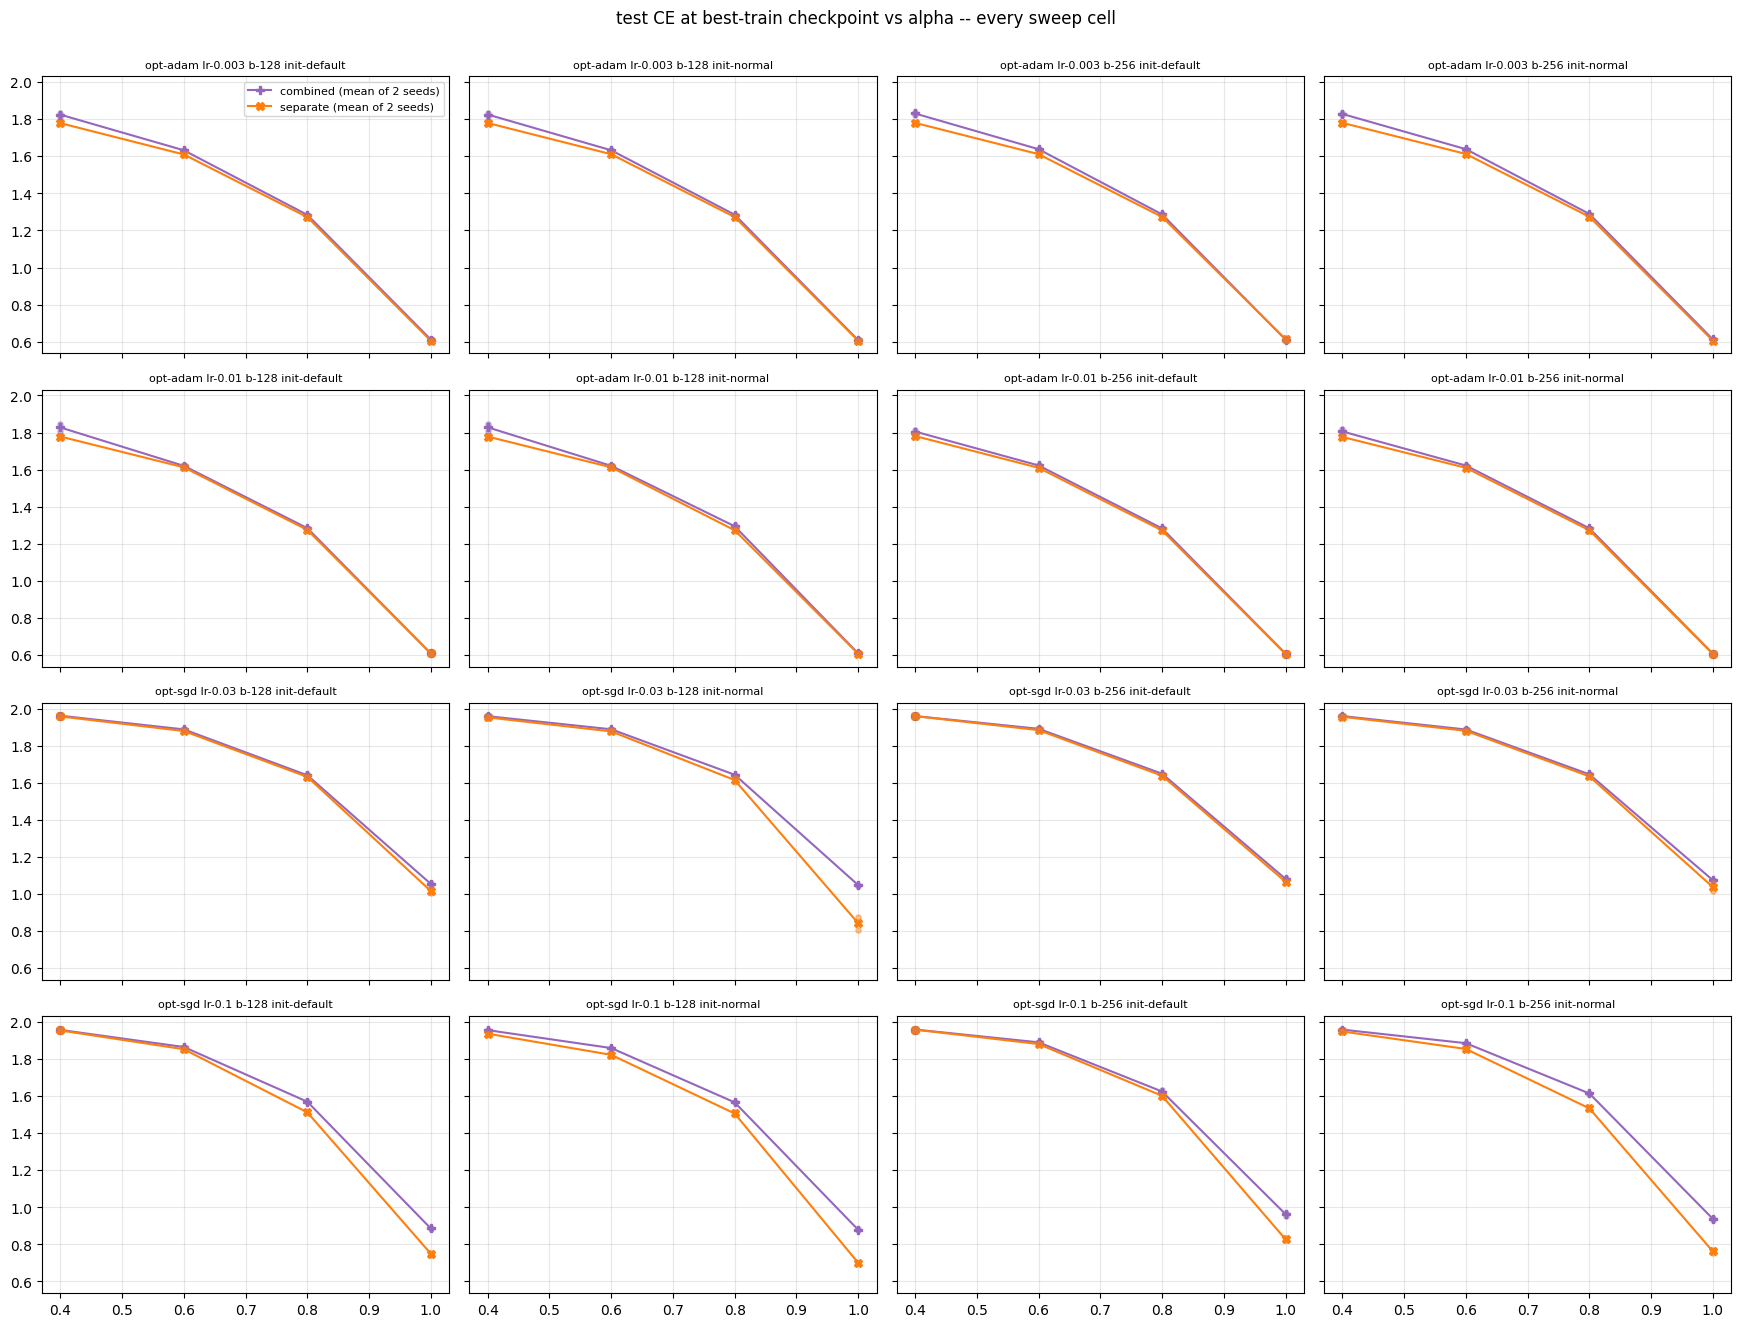

saved -> artifacts/ce_vs_alpha_ALL_CELLS.png


In [5]:
if cells_found:
    ncols = 4
    nrows = int(np.ceil(len(cells_found) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.3 * nrows),
                             squeeze=False, sharex=True, sharey=True)
    for i, cell in enumerate(cells_found):
        ax = axes[i // ncols][i % ncols]
        plot_cell(cell, ax)
        ax.set_title(cell.replace('_', ' '), fontsize=8)
        ax.set_xlabel(''); ax.set_ylabel('')
        if i > 0 and ax.get_legend(): ax.get_legend().remove()
    for j in range(len(cells_found), nrows * ncols):
        axes[j // ncols][j % ncols].axis('off')
    fig.suptitle('test CE at best-train checkpoint vs alpha -- every sweep cell', y=1.002)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, 'ce_vs_alpha_ALL_CELLS.png'), dpi=130,
                bbox_inches='tight')
    plt.show()
    print(f'saved -> {ARTIFACTS_DIR}/ce_vs_alpha_ALL_CELLS.png')


## Training curves per cell

Solid = combined, dashed = separate; one color per threshold; thin lines = individual seeds.
Curves START AT EPOCH 0 (the random init) by construction. Saved to
`artifacts/curves_<cell>.png`.


In [11]:
CURVE_SPLIT = 'train_loss'   # 'test_loss' or 'train_loss'
DIVERGE_CUTOFF = 5.0   # nats -- a healthy run here stays in ~[0, 2]; anything above this is an
                        # Adam instability spike (observed in 7/256 runs, all separate, thr=1.0,
                        # adam lr=0.01), not a real point on the loss surface. Skipped from the
                        # line plot (not deleted from disk) so a rare spike can't wreck a whole
                        # cell's y-axis; every skip is printed below.

thr_colors = plt.cm.viridis(np.linspace(0, 0.9, 4))
skipped = []
for cell in cells_found:
    thrs_all = sorted({t for arch in by_cell[cell].values() for t in arch})
    cmap = {t: thr_colors[i % len(thr_colors)] for i, t in enumerate(thrs_all)}
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for arch, ls in [('combined', '-'), ('separate', '--')]:
        for t in sorted(by_cell[cell][arch]):
            for r in by_cell[cell][arch][t]:
                curve = r['history'][CURVE_SPLIT]
                if max(curve) > DIVERGE_CUTOFF:
                    skipped.append((cell, arch, r['seed'], t, max(curve)))
                    continue
                ax.plot(curve, ls, color=cmap[t], lw=0.9, alpha=0.8)
    handles = ([plt.Line2D([], [], color=cmap[t], label=f'a={t}') for t in thrs_all] +
               [plt.Line2D([], [], color='k', ls='-', label='combined'),
                plt.Line2D([], [], color='k', ls='--', label='separate')])
    ax.legend(handles=handles, fontsize=7)
    ax.set_xlabel('epoch (0 = random init)'); ax.set_ylabel(f'{CURVE_SPLIT} (nats)')
    ax.set_title(cell, fontsize=10); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, f'curves_{cell}.png'), dpi=130)
    plt.close(fig)
print(f'saved {len(cells_found)} figures -> {ARTIFACTS_DIR}/curves_<cell>.png')
if skipped:
    print(f'\n{len(skipped)} run(s) excluded from the curve plots (max {CURVE_SPLIT} > {DIVERGE_CUTOFF} nats):')
    for cell, arch, seed, t, mx in skipped:
        print(f'  {cell:42s} {arch:9s} seed{seed} thr{t}  max={mx:.1f}')
    print('  (best_train / test_at_best for these runs are unaffected -- checkpointing selects')
    print('   the pre-spike epoch, so aggregate CE tables/plots elsewhere are not impacted)')


saved 16 figures -> artifacts/curves_<cell>.png

7 run(s) excluded from the curve plots (max train_loss > 5.0 nats):
  opt-adam_lr-0.01_b-128_init-default        separate  seed0 thr1.0  max=1431.5
  opt-adam_lr-0.01_b-128_init-default        separate  seed1 thr1.0  max=896.0
  opt-adam_lr-0.01_b-128_init-normal         separate  seed0 thr1.0  max=5070.2
  opt-adam_lr-0.01_b-256_init-default        separate  seed0 thr1.0  max=410.8
  opt-adam_lr-0.01_b-256_init-default        separate  seed1 thr1.0  max=245.6
  opt-adam_lr-0.01_b-256_init-normal         separate  seed0 thr1.0  max=1671.8
  opt-adam_lr-0.01_b-256_init-normal         separate  seed1 thr1.0  max=4537.3
  (best_train / test_at_best for these runs are unaffected -- checkpointing selects
   the pre-spike epoch, so aggregate CE tables/plots elsewhere are not impacted)


(separate seed0/seed1, thr=1.0 in opt-adam_lr-0.01_b-256_init-normal) 

## Numeric summary table

Per (cell, threshold): mean test CE per arch over seeds, the gap (combined - separate;
positive = separate better), and the seed-to-seed spread -- the quick read on where the
finding survives.


In [7]:
print(f'{"cell":44s} {"thr":>5s} {"comb":>8s} {"sep":>8s} {"gap":>8s} {"seed-spread":>11s}')
for cell in cells_found:
    thrs = sorted({t for arch in by_cell[cell].values() for t in arch})
    for t in thrs:
        vc = [r['test_at_best'] for r in by_cell[cell]['combined'][t]]
        vs = [r['test_at_best'] for r in by_cell[cell]['separate'][t]]
        if not vc or not vs:
            continue
        spread = max(np.ptp(vc), np.ptp(vs))
        print(f'{cell:44s} {t:5.2f} {np.mean(vc):8.4f} {np.mean(vs):8.4f} '
              f'{np.mean(vc) - np.mean(vs):+8.4f} {spread:11.4f}')


cell                                           thr     comb      sep      gap seed-spread
opt-adam_lr-0.003_b-128_init-default          0.40   1.8247   1.7790  +0.0457      0.0214
opt-adam_lr-0.003_b-128_init-default          0.60   1.6324   1.6100  +0.0225      0.0008
opt-adam_lr-0.003_b-128_init-default          0.80   1.2840   1.2719  +0.0120      0.0009
opt-adam_lr-0.003_b-128_init-default          1.00   0.6116   0.6046  +0.0070      0.0079
opt-adam_lr-0.003_b-128_init-normal           0.40   1.8255   1.7797  +0.0458      0.0212
opt-adam_lr-0.003_b-128_init-normal           0.60   1.6326   1.6114  +0.0212      0.0008
opt-adam_lr-0.003_b-128_init-normal           0.80   1.2849   1.2725  +0.0124      0.0002
opt-adam_lr-0.003_b-128_init-normal           1.00   0.6078   0.6049  +0.0029      0.0008
opt-adam_lr-0.003_b-256_init-default          0.40   1.8310   1.7805  +0.0505      0.0182
opt-adam_lr-0.003_b-256_init-default          0.60   1.6384   1.6117  +0.0267      0.0014
opt-adam_l